# Day 2 · Lines — The Jet Stream
### #30DayMapChallenge 2026 · ECMWF 9 km open data

The **250 hPa wind** drawn two ways at once: a glowing *isotach* field (wind speed by
brightness) with the flow itself traced as fine **streamlines**. Together they show the
polar-front **jet stream** — the river of fast air near the tropopause that steers our
weather — meandering across Europe and the eastern Atlantic.

This notebook is self-contained: **method, code, output, tools and licence** in one place,
runnable on any laptop with `pip`.

## Method

- The jet lives near **250 hPa** (~10 km up). Its core can exceed **60–70 m/s** (>250 km/h).
- We fetch the **u** and **v** wind components on that level, compute speed `|V| = √(u²+v²)`,
  and render speed as a filled field.
- We overlay **streamlines** — paths tangent to the wind — so the eye follows the flow:
  troughs, ridges and cut-off lows appear as the lines buckle and spin.
- Colour encodes speed through **lightness** (dark = calm → bright = jet core), which keeps
  the map legible for colourblind viewers and in greyscale (see the *Colour* note below).

## Licence & attribution

Access to ECMWF Open Data is governed by the **Creative Commons CC-BY-4.0** licence and the
associated [Terms of Use](https://apps.ecmwf.int/datasets/licences/general/).

> In applying this licence, ECMWF does not waive the privileges and immunities granted to it
> by virtue of its status as an intergovernmental organisation.

When you share a map made from this data, attribute it:
`© ECMWF · Source: www.ecmwf.int · Licence: CC-BY-4.0 and ECMWF Terms of Use`

## Tools

| Tool | Role |
|---|---|
| [`ecmwf-opendata`](https://github.com/ecmwf/ecmwf-opendata) | retrieve IFS open data (the ECMWF API client) |
| [`earthkit-data`](https://earthkit-data.readthedocs.io) | read & handle the GRIB (modern ECMWF stack) |
| `cartopy` + `matplotlib` | projection, coastlines, the custom render |
| `scipy` | needed by cartopy's `streamplot` |

ECMWF's own Open Charts example plots with **Metview**; we use **earthkit + matplotlib**
instead because it is `pip`-installable (no conda binary) and does the custom streamline
art — same API, more portable.

In [1]:
# Run once if needed (uncomment):
#!pip install earthkit-data ecmwf-opendata cartopy matplotlib scipy

In [2]:
import os
import numpy as np
import xarray as xr
import earthkit.data as ekd
from ecmwf.opendata import Client
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import cartopy.crs as ccrs
import cartopy.feature as cfeature

### Configuration

`DATE = 0` pulls **today's** run, so re-running on **2 November 2026** produces that day's
jet with no edits. Pin a specific day with e.g. `DATE = "20261102"`.

In [3]:
DATE   = 0                      # 0 = today's run; or "20261102"
TIME   = 0                      # 00Z cycle
STEP   = 0                      # forecast step in hours (0 = analysis time)
LEVEL  = 250                    # hPa — jet-stream level
REGION = [-30, 45, 30, 72]      # W, E, S, N — Europe + eastern Atlantic
GRIB   = "data/day02_jet250.grib2"


## Retrieve Data

Two parameters on one pressure level
([u = 131](https://codes.ecmwf.int/grib/param-db/131),
[v = 132](https://codes.ecmwf.int/grib/param-db/132)).

The Client **defaults to 0.25°** — pass `resol="0p1"` to get the real **0.1° (~9 km)** grid.

In [4]:
os.makedirs("data", exist_ok=True)
Client("ecmwf").retrieve(
    date=DATE, time=TIME, step=STEP,
    stream="oper", type="fc",
    levtype="pl", levelist=LEVEL, param=["u", "v"],
    resol="0p1",                 # <-- the 9 km grid; without this you get 0.25deg
    target=GRIB,
)
# earthkit-data can also retrieve directly, in one line:
#   ds = ekd.from_source("ecmwf-open-data", date=DATE, time=TIME, step=STEP,
#          levtype="pl", levelist=LEVEL, param=["u","v"], resol="0p1")
# We download to a file so re-runs are reproducible and offline-friendly.

To ensure the stability of our systems and to preserve resources for our operational activities (network, compute, etc.), access to the open-data portal is limited to 500 simultaneous connections. This limit helps us guarantee reliable service for our operational users, especially during periods of high demand. For added reliability, the open-data is replicated across AWS, Azure, and Google Cloud. If you experience difficulties accessing the portal directly, you can also retrieve the data from these cloud platforms.


Resolution '0p1' does not match the client resolution '0p25', using resolution '0p1' from retrieve


20261028000000-0h-oper-fc-pl.grib2:   0%|          | 0.00/4.99M [00:00<?, ?B/s]

20261028000000-0h-oper-fc-pl.grib2:   3%|▎         | 138k/4.99M [00:00<00:03, 1.40MB/s]

20261028000000-0h-oper-fc-pl.grib2:  18%|█▊        | 938k/4.99M [00:00<00:00, 5.36MB/s]

20261028000000-0h-oper-fc-pl.grib2:  30%|██▉       | 1.48M/4.99M [00:00<00:00, 4.59MB/s]

20261028000000-0h-oper-fc-pl.grib2:  50%|█████     | 2.51M/4.99M [00:00<00:00, 6.65MB/s]

20261028000000-0h-oper-fc-pl.grib2:  68%|██████▊   | 3.41M/4.99M [00:00<00:00, 7.49MB/s]

20261028000000-0h-oper-fc-pl.grib2:  86%|████████▌ | 4.28M/4.99M [00:00<00:00, 7.97MB/s]

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


## Reading and processing

Read the GRIB with **earthkit-data**, move to `xarray`, and tidy the grid
(longitudes to −180…180 ascending, latitudes ascending) so the plotters behave.

In [5]:
ds = ekd.from_source("file", GRIB)
x  = ds.to_xarray().squeeze()

lon = x["longitude"].values.copy()
lat = x["latitude"].values.copy()
u, v = x["u"].values, x["v"].values

lon = ((lon + 180) % 360) - 180          # wrap to -180..180
order = np.argsort(lon)
lon, u, v = lon[order], u[:, order], v[:, order]
if lat[0] > lat[-1]:                      # make latitude ascending
    lat, u, v = lat[::-1], u[::-1], v[::-1]

# subset to the region (+margin) before plotting — faster
mx = (lon >= REGION[0] - 5) & (lon <= REGION[1] + 5)
my = (lat >= REGION[2] - 5) & (lat <= REGION[3] + 5)
lon, lat = lon[mx], lat[my]
u, v = u[np.ix_(my, mx)], v[np.ix_(my, mx)]
speed = np.hypot(u, v)

VALID = str(xr.open_dataset(GRIB, engine="cfgrib")["valid_time"].values)[:16].replace("T", " ") + " UTC"
print(f"grid {speed.shape} at {abs(lat[1]-lat[0]):.2f} deg   valid {VALID}")
print(f"jet max: {np.nanmax(speed):.0f} m/s  (~{np.nanmax(speed)*3.6:.0f} km/h)")

earthkit-data cache: filesystem usage (96%) exceeds limit (95%) set by 'maximum-cache-disk-usage' config option


earthkit-data cache: trying to free 4.6 GiB


earthkit-data cache: could not free 4.6 GiB


Ignoring index file 'data/day02_jet250.grib2.5b7b6.idx' older than GRIB file


grid (520, 851) at 0.10 deg   valid 2026-10-28 00:00 UTC
jet max: 66 m/s  (~238 km/h)


## Plotting

### Colour — why this ramp is colourblind-safe
Wind speed is encoded by **lightness** (dark navy → warm white), not hue. Lightness is the
one channel every form of colour-vision deficiency keeps, so the jet reads correctly for
deuteran/protan/tritan viewers and even in pure greyscale. The ramp below was tuned to be
**monotonically increasing in luminance**. For a by-construction-safe alternative, swap in
`cividis` (one line, commented).

In [6]:
# luminance-monotonic ramp: speed read by brightness, not hue  -> colourblind-safe
JET = LinearSegmentedColormap.from_list(
    "jetflow", ["#0b1733", "#15568c", "#2aa6cf", "#8fe0e6", "#fff6d5"])
# Accessibility-purist alternative:
# JET = plt.get_cmap("cividis")

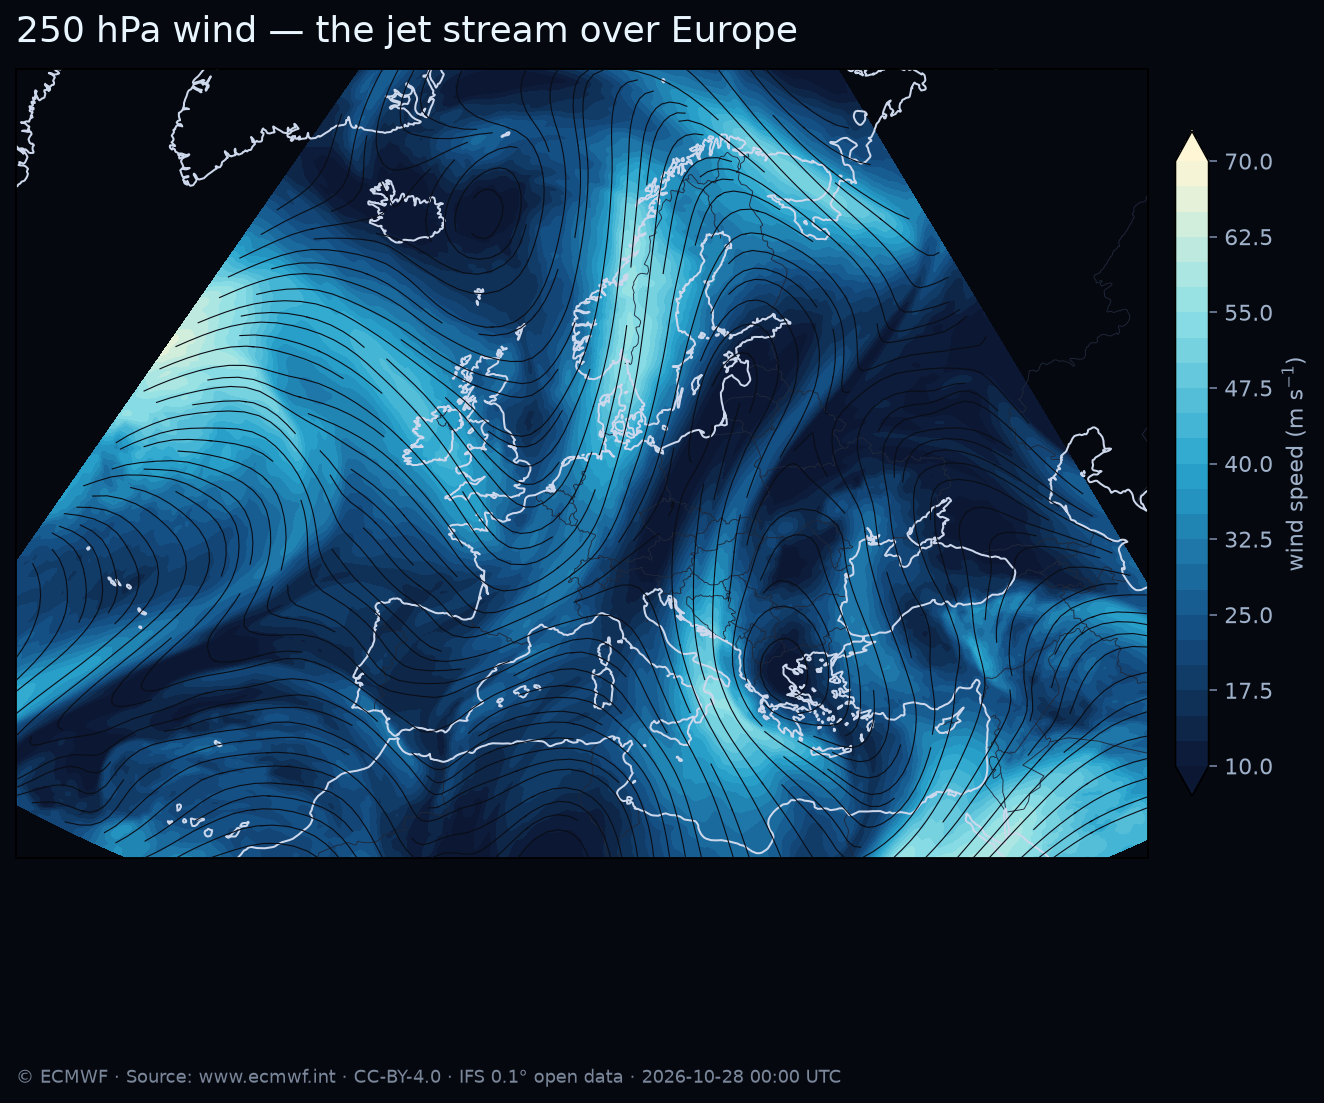

In [7]:
BG = "#05080f"
proj = ccrs.LambertConformal(central_longitude=10, central_latitude=52,
                             standard_parallels=(35, 65))
tp = dict(transform=ccrs.PlateCarree())

fig = plt.figure(figsize=(11, 9), dpi=160)
fig.patch.set_facecolor(BG)
ax = plt.axes(projection=proj)
ax.set_extent(REGION, crs=ccrs.PlateCarree())
ax.set_facecolor(BG)

# isotach glow
cf = ax.contourf(lon, lat, speed, levels=np.linspace(10, 70, 25),
                 cmap=JET, extend="both", zorder=0, **tp)
# geography
ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="#20283a", linewidth=0.4, zorder=1)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor="#cdd8ec", linewidth=0.9, zorder=2)
# the flow itself
ax.streamplot(lon, lat, u, v, color="#0a0d16", density=2.4,
              linewidth=0.5, arrowstyle="-", zorder=3, **tp)

cb = fig.colorbar(cf, ax=ax, shrink=0.6, pad=0.02, label="wind speed (m s$^{-1}$)")
cb.ax.yaxis.label.set_color("#9fb0c9"); cb.ax.tick_params(colors="#6d7c99")
plt.setp(plt.getp(cb.ax, "yticklabels"), color="#9fb0c9")

ax.set_title("250 hPa wind — the jet stream over Europe",
             color="#eaf6ff", fontsize=16, loc="left", pad=12)

fig.text(0.125, 0.065,
         f"© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 · IFS 0.1° open data · {VALID}",
         color="#7a8699", fontsize=8)

fig.savefig("day02_lines_jet.png", facecolor=fig.get_facecolor(), bbox_inches="tight")
plt.show()

## Note

Open Data is published at **0.1° (~9 km)** and **0.25°**; the `resol="0p1"` flag above
selects the finer grid. Maps from open data differ slightly from ECMWF Open Charts, which
use the full-resolution operational model.

**Saved:** `day02_lines_jet.png` — ready to post.

*Part of a #30DayMapChallenge 2026 series built on ECMWF (and MeteoSwiss) open data.
Day 20 is Hexagons — ECMWF 9 km hexbins with a MeteoSwiss 1 km nested inset.*